In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset downloading
import os
import zipfile
import urllib.request

# Feature engineering
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.preprocessing import normalize

# Similarity calculation
from sklearn.metrics.pairwise import cosine_similarity

# Sparse matrix handling
from scipy.sparse import hstack

# Evaluation
from sklearn.metrics import mean_squared_error

# Warnings
import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# Dataset URL
dataset_url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"

# Download location
zip_path = "movielens.zip"

# Download dataset if it does not already exist
if not os.path.exists(zip_path):
    urllib.request.urlretrieve(dataset_url, zip_path)
    print("Dataset downloaded successfully!")

# Extract dataset
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

# Load CSV files
movies = pd.read_csv("ml-latest-small/movies.csv")
ratings = pd.read_csv("ml-latest-small/ratings.csv")

print("Movies Dataset:")
display(movies.head())

print("Ratings Dataset:")
display(ratings.head())

Dataset downloaded successfully!
Movies Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [3]:
# Dataset dimensions
print("Movies Dataset Shape:", movies.shape)
print("Ratings Dataset Shape:", ratings.shape)

# Column information
print("\nMovies Dataset Information:")
movies.info()

print("\nRatings Dataset Information:")
ratings.info()

# Statistical summary
print("\nMovies Dataset Summary:")
display(movies.describe(include='all'))

print("\nRatings Dataset Summary:")
display(ratings.describe())

# Missing values
print("\nMissing Values in Movies:")
print(movies.isnull().sum())

print("\nMissing Values in Ratings:")
print(ratings.isnull().sum())

# Duplicate records
print("\nDuplicate Movie Records:", movies.duplicated().sum())
print("Duplicate Rating Records:", ratings.duplicated().sum())

Movies Dataset Shape: (9742, 3)
Ratings Dataset Shape: (100836, 4)

Movies Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

Ratings Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB

Movies Dataset Summary:


,movieId,title,genres
count,9742.000000,9742,9742
unique,NaN,9737,951
top,NaN,Emma (1996),Drama
freq,NaN,2,1053
mean,42200.353623,NaN,NaN
std,52160.494854,NaN,NaN
min,1.000000,NaN,NaN
25%,3248.250000,NaN,NaN
50%,7300.000000,NaN,NaN
75%,76232.000000,NaN,NaN



Ratings Dataset Summary:


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09



Missing Values in Movies:
movieId    0
title      0
genres     0
dtype: int64

Missing Values in Ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate Movie Records: 0
Duplicate Rating Records: 0


Total Movies: 9742
Total Users: 610
Total Ratings: 100836


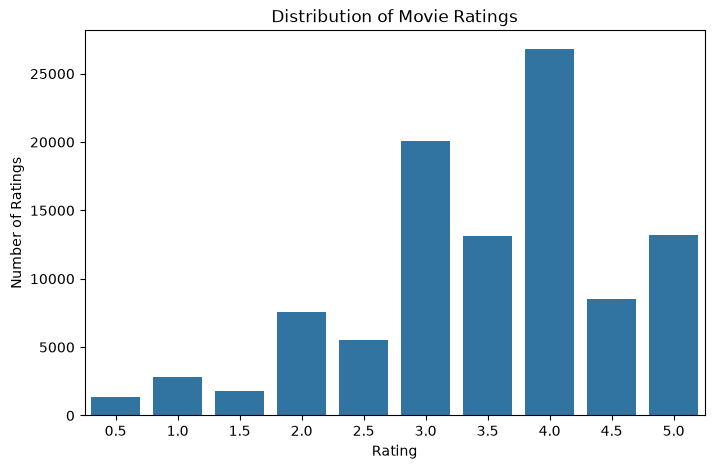

In [4]:
# Total movies and users
print("Total Movies:", movies['movieId'].nunique())
print("Total Users:", ratings['userId'].nunique())
print("Total Ratings:", len(ratings))

# Distribution of ratings
plt.figure(figsize=(8, 5))

sns.countplot(
    data=ratings,
    x='rating'
)

plt.title("Distribution of Movie Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.show()

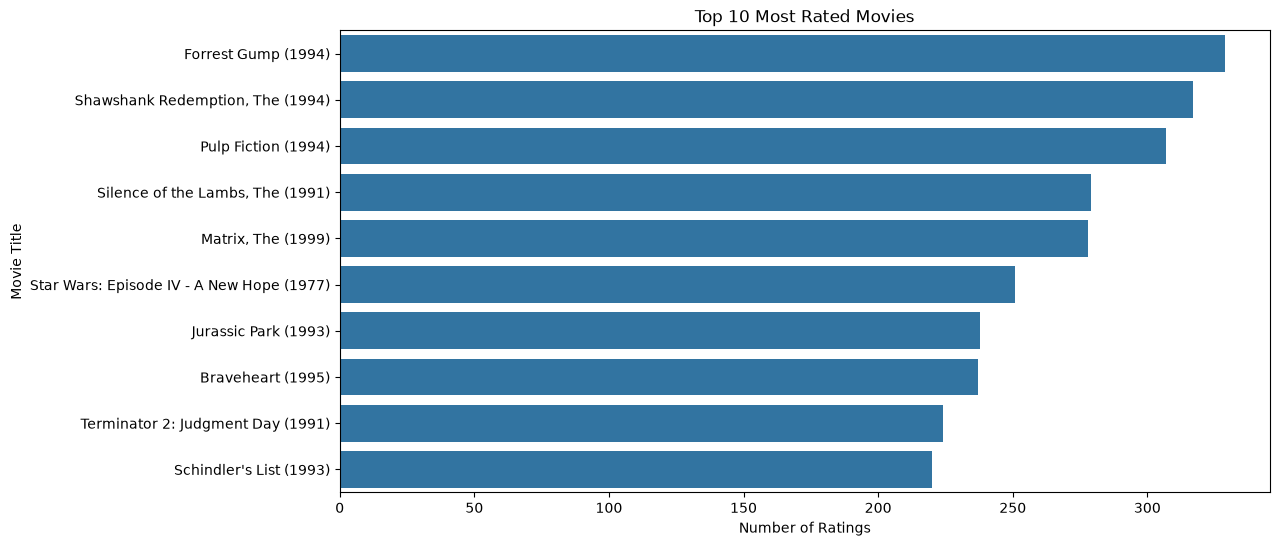

In [5]:
# Most frequently rated movies
popular_movies = ratings['movieId'].value_counts().head(10)

popular_movies = popular_movies.reset_index()
popular_movies.columns = ['movieId', 'rating_count']

popular_movies = popular_movies.merge(
    movies,
    on='movieId'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=popular_movies,
    x='rating_count',
    y='title'
)

plt.title("Top 10 Most Rated Movies")
plt.xlabel("Number of Ratings")
plt.ylabel("Movie Title")
plt.show()

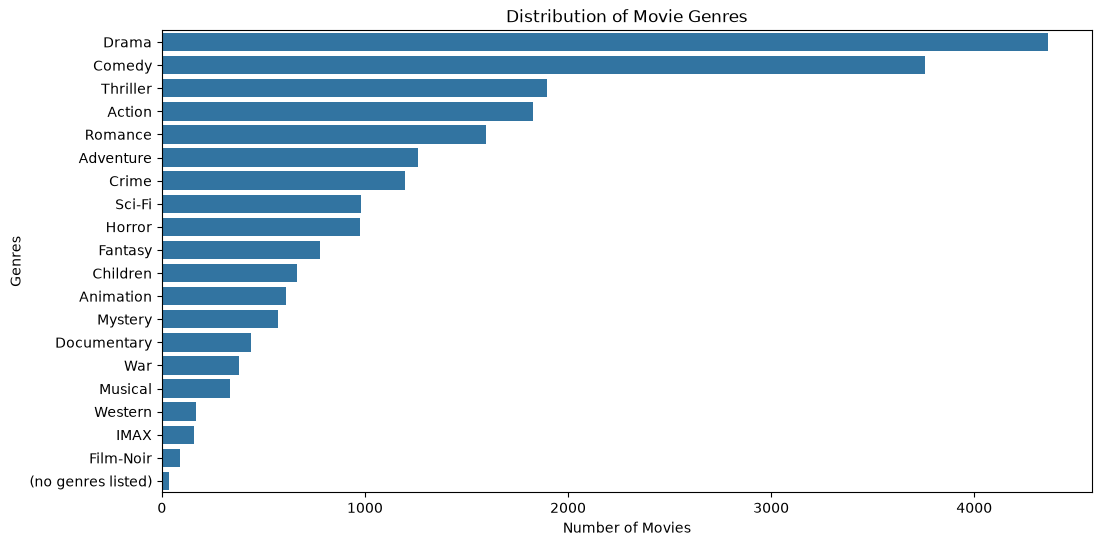

In [6]:
# Analyse movie genres
genre_list = movies['genres'].str.split('|').explode()

genre_counts = genre_list.value_counts()

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title("Distribution of Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genres")
plt.show()

In [7]:
# Create copies of original datasets
movies = movies.copy()
ratings = ratings.copy()

# Remove duplicate records
movies.drop_duplicates(subset='movieId', inplace=True)

ratings.drop_duplicates(
    subset=['userId', 'movieId'],
    keep='last',
    inplace=True
)

# Remove missing values
movies.dropna(subset=['movieId', 'title', 'genres'], inplace=True)

ratings.dropna(
    subset=['userId', 'movieId', 'rating'],
    inplace=True
)

# Remove invalid ratings
ratings = ratings[
    ratings['rating'].between(0.5, 5.0)
]

# Remove movies without meaningful genre information
movies = movies[
    movies['genres'] != '(no genres listed)'
]

# Keep only ratings belonging to available movies
ratings = ratings[
    ratings['movieId'].isin(movies['movieId'])
]

# Reset indexes
movies.reset_index(drop=True, inplace=True)
ratings.reset_index(drop=True, inplace=True)

print("Data cleaning completed!")

print("Cleaned Movies Shape:", movies.shape)
print("Cleaned Ratings Shape:", ratings.shape)

print("\nRemaining Missing Values:")
print(movies.isnull().sum())
print(ratings.isnull().sum())

Data cleaning completed!
Cleaned Movies Shape: (9708, 3)
Cleaned Ratings Shape: (100789, 4)

Remaining Missing Values:
movieId    0
title      0
genres     0
dtype: int64
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64


In [8]:
# Convert genre strings into lists
movies['genre_list'] = movies['genres'].apply(
    lambda x: x.split('|')
)

# Apply Multi-Hot Encoding
mlb = MultiLabelBinarizer()

genre_features = mlb.fit_transform(
    movies['genre_list']
)

print("Available Genres:")
print(mlb.classes_)

print("\nGenre Feature Matrix Shape:")
print(genre_features.shape)

Available Genres:
['Action' 'Adventure' 'Animation' 'Children' 'Comedy' 'Crime'
 'Documentary' 'Drama' 'Fantasy' 'Film-Noir' 'Horror' 'IMAX' 'Musical'
 'Mystery' 'Romance' 'Sci-Fi' 'Thriller' 'War' 'Western']

Genre Feature Matrix Shape:
(9708, 19)


In [9]:
# Convert movie titles into TF-IDF features
tfidf = TfidfVectorizer(
    stop_words='english',
    ngram_range=(1, 2),
    max_features=5000
)

title_features = tfidf.fit_transform(
    movies['title']
)

print("Title Feature Matrix Shape:")
print(title_features.shape)

Title Feature Matrix Shape:
(9708, 5000)


In [10]:
# Normalize genre features
genre_features = normalize(genre_features)

# Normalize title features
title_features = normalize(title_features)

# Combine both feature sets
# Genres have 70% importance
# Movie titles have 30% importance

feature_matrix = hstack([
    genre_features * np.sqrt(0.7),
    title_features * np.sqrt(0.3)
]).tocsr()

# Normalize combined feature matrix
feature_matrix = normalize(feature_matrix)

print("Combined Feature Matrix Shape:")
print(feature_matrix.shape)

print("Feature engineering completed successfully!")

Combined Feature Matrix Shape:
(9708, 5019)
Feature engineering completed successfully!


In [11]:
# Keep users who have at least 5 ratings
user_rating_counts = ratings.groupby('userId').size()

eligible_users = user_rating_counts[
    user_rating_counts >= 5
].index

filtered_ratings = ratings[
    ratings['userId'].isin(eligible_users)
].copy()

# Randomly split each user's ratings
train_parts = []
test_parts = []

for user_id, group in filtered_ratings.groupby('userId'):

    group = group.sample(
        frac=1,
        random_state=42
    )

    split_index = int(len(group) * 0.8)

    train_parts.append(group.iloc[:split_index])
    test_parts.append(group.iloc[split_index:])

# Combine all user splits
train_data = pd.concat(train_parts).reset_index(drop=True)
test_data = pd.concat(test_parts).reset_index(drop=True)

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

print("\nTraining Percentage:",
      round(len(train_data) / len(filtered_ratings) * 100, 2), "%")

print("Testing Percentage:",
      round(len(test_data) / len(filtered_ratings) * 100, 2), "%")

Training Dataset Shape: (80380, 4)
Testing Dataset Shape: (20409, 4)

Training Percentage: 79.75 %
Testing Percentage: 20.25 %


In [12]:
# Calculate movie-to-movie cosine similarity
# Sparse output saves memory

movie_similarity = cosine_similarity(
    feature_matrix,
    dense_output=False
)

print("Movie similarity matrix created!")
print("Similarity Matrix Shape:", movie_similarity.shape)

Movie similarity matrix created!
Similarity Matrix Shape: (9708, 9708)


In [13]:
# Create movie ID to index mapping
movie_to_index = pd.Series(
    movies.index,
    index=movies['movieId']
)

# Recommendation function
def recommend_movies(user_id, n=10):

    # Get movies rated by the selected user
    user_ratings = train_data[
        train_data['userId'] == user_id
    ]

    # Identify highly rated movies
    liked_movies = user_ratings[
        user_ratings['rating'] >= 4
    ]

    # Check whether the user has liked any movies
    if liked_movies.empty:
        print("Not enough liked movies to generate recommendations.")
        return pd.DataFrame()

    # Get indexes of liked movies
    liked_indices = movie_to_index.loc[
        liked_movies['movieId']
    ].values

    # Calculate average similarity with liked movies
    scores = np.asarray(
        movie_similarity[liked_indices].mean(axis=0)
    ).ravel()

    # Identify movies already watched by the user
    watched_movie_ids = set(user_ratings['movieId'])

    # Create candidate movie list
    candidate_mask = ~movies['movieId'].isin(
        watched_movie_ids
    ).values

    # Exclude already watched movies
    scores[~candidate_mask] = -1

    # Select top N movies
    top_indices = np.argsort(scores)[::-1][:n]

    # Create recommendation results
    recommendations = movies.iloc[top_indices][
        ['movieId', 'title', 'genres']
    ].copy()

    recommendations['similarity_score'] = scores[top_indices]

    return recommendations.reset_index(drop=True)


print("Recommendation model implemented successfully!")

Recommendation model implemented successfully!


In [14]:
# Select a user with the most highly rated movies
liked_counts = (
    train_data[train_data['rating'] >= 4]
    .groupby('userId')
    .size()
)

# Select user with maximum liked movies
sample_user = liked_counts.idxmax()

print("Selected User ID:", sample_user)

# Generate recommendations
recommendations = recommend_movies(
    sample_user,
    n=10
)

print("\nRecommended Movies:")
display(recommendations)

Selected User ID: 414

Recommended Movies:


,movieId,title,genres,similarity_score
0,27306,Bartleby (2001),Comedy|Drama,0.328504
1,5890,Elling (2001),Comedy|Drama,0.328504
2,6376,Respiro (2002),Comedy|Drama,0.327453
3,3901,Duets (2000),Comedy|Drama,0.327275
4,4646,Greenfingers (2000),Comedy|Drama,0.327275
5,3565,Where the Heart Is (2000),Comedy|Drama,0.324196
6,2596,SLC Punk! (1998),Comedy|Drama,0.324095
7,96,In the Bleak Midwinter (1995),Comedy|Drama,0.324037
8,171,Jeffrey (1995),Comedy|Drama,0.324037
9,304,Roommates (1995),Comedy|Drama,0.324037


In [15]:
# Display movies liked by the selected user

user_liked_movies = train_data[
    (train_data['userId'] == sample_user) &
    (train_data['rating'] >= 4)
]

user_liked_movies = user_liked_movies.merge(
    movies[['movieId', 'title', 'genres']],
    on='movieId'
)

print("Movies Previously Liked by User:")
display(
    user_liked_movies[
        ['title', 'genres', 'rating']
    ].head(10)
)

Movies Previously Liked by User:


,title,genres,rating
0,Charlie's Angels (2000),Action|Comedy,4.0
1,Lawrence of Arabia (1962),Adventure|Drama|War,5.0
2,Hell or High Water (2016),Crime|Drama,5.0
3,Billy Elliot (2000),Drama,4.0
4,Volunteers (1985),Comedy,5.0
5,Heavy Metal (1981),Action|Adventure|Animation|Horror|Sci-Fi,4.0
6,Midnight in Paris (2011),Comedy|Fantasy|Romance,4.0
7,"Adventures of Baron Munchausen, The (1988)",Adventure|Comedy|Fantasy,4.0
8,Kiss Kiss Bang Bang (2005),Comedy|Crime|Mystery|Thriller,4.0
9,American Pop (1981),Animation|Musical,4.0


In [16]:
# Create a function to evaluate recommendations

def evaluate_recommendations(n=10):

    precision_scores = []
    recall_scores = []

    # Consider users who have at least one relevant
    # movie in the testing dataset
    test_users = test_data[
        test_data['rating'] >= 4
    ]['userId'].unique()

    for user_id in test_users:

        # Get relevant movies from test data
        relevant_movies = set(
            test_data[
                (test_data['userId'] == user_id) &
                (test_data['rating'] >= 4)
            ]['movieId']
        )

        # Generate recommendations
        recommended = recommend_movies(
            user_id,
            n=n
        )

        if recommended.empty:
            continue

        recommended_movies = set(
            recommended['movieId']
        )

        # Calculate relevant recommended movies
        correct_recommendations = (
            relevant_movies & recommended_movies
        )

        # Precision
        precision = (
            len(correct_recommendations) / n
        )

        # Recall
        recall = (
            len(correct_recommendations) /
            len(relevant_movies)
        )

        precision_scores.append(precision)
        recall_scores.append(recall)

    # Calculate average metrics
    avg_precision = np.mean(precision_scores)
    avg_recall = np.mean(recall_scores)

    return avg_precision, avg_recall


print("Testing the recommendation model...")

precision, recall = evaluate_recommendations(10)

print("\nTesting Results:")
print("Precision@10:", round(precision, 4))
print("Recall@10:", round(recall, 4))

Testing the recommendation model...

Testing Results:
Precision@10: 0.0128
Recall@10: 0.019


In [17]:
# Function to predict a user's rating for a movie

def predict_rating(user_id, movie_id):

    # Get user's training ratings
    user_history = train_data[
        train_data['userId'] == user_id
    ]

    if user_history.empty:
        return train_data['rating'].mean()

    # Get movie indexes
    target_index = movie_to_index[movie_id]

    history_indices = movie_to_index.loc[
        user_history['movieId']
    ].values

    # Get similarity scores
    similarities = movie_similarity[
        target_index,
        history_indices
    ].toarray().ravel()

    # Get actual training ratings
    user_ratings = user_history['rating'].values

    # Calculate similarity-weighted rating
    if similarities.sum() > 0:

        predicted = np.dot(
            similarities,
            user_ratings
        ) / similarities.sum()

    else:
        predicted = user_ratings.mean()

    # Keep predicted ratings within valid range
    return np.clip(predicted, 0.5, 5.0)

In [18]:
# Predict ratings for the testing dataset

actual_ratings = []
predicted_ratings = []

for row in test_data.itertuples(index=False):

    actual_ratings.append(row.rating)

    predicted = predict_rating(
        row.userId,
        row.movieId
    )

    predicted_ratings.append(predicted)

# Calculate RMSE
rmse = np.sqrt(
    mean_squared_error(
        actual_ratings,
        predicted_ratings
    )
)

print("Root Mean Squared Error (RMSE):",
      round(rmse, 4))

Root Mean Squared Error (RMSE): 0.9185


,Metric,Value
0,Precision@10,0.012833
1,Recall@10,0.019017
2,RMSE,0.918501


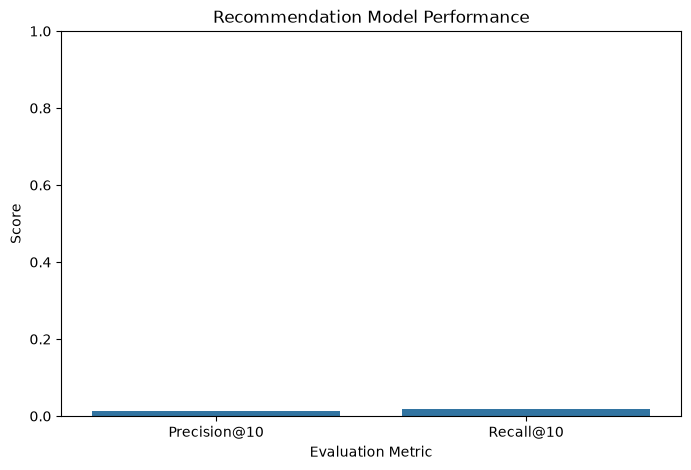

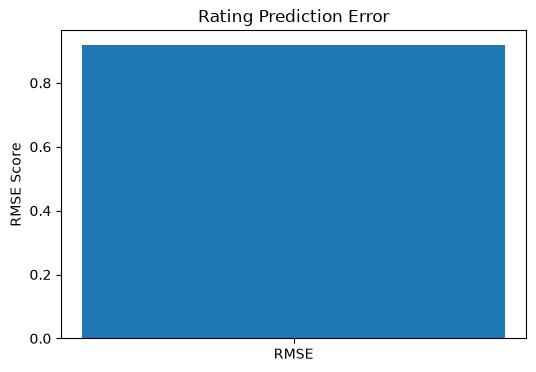

In [19]:
# Prepare evaluation metrics
metrics = pd.DataFrame({
    'Metric': [
        'Precision@10',
        'Recall@10',
        'RMSE'
    ],
    'Value': [
        precision,
        recall,
        rmse
    ]
})

display(metrics)

# Visualize Precision and Recall
plt.figure(figsize=(8, 5))

sns.barplot(
    data=metrics.iloc[:2],
    x='Metric',
    y='Value'
)

plt.title("Recommendation Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)

plt.show()

# Visualize RMSE separately
plt.figure(figsize=(6, 4))

plt.bar(
    ['RMSE'],
    [rmse]
)

plt.title("Rating Prediction Error")
plt.ylabel("RMSE Score")

plt.show()

In [20]:
print("=" * 45)
print("       MOVIE RECOMMENDATION SYSTEM")
print("=" * 45)

print("\nModel: Content-Based Filtering")

print("\nFeature Engineering:")
print("1. Multi-Hot Encoding for movie genres")
print("2. TF-IDF Vectorization for movie titles")
print("3. Cosine Similarity for movie comparison")

print("\nEvaluation Results:")
print("Precision@10:", round(precision, 4))
print("Recall@10:", round(recall, 4))
print("RMSE:", round(rmse, 4))

print("\nModel Status: Successfully Tested")

print("=" * 45)

       MOVIE RECOMMENDATION SYSTEM

Model: Content-Based Filtering

Feature Engineering:
1. Multi-Hot Encoding for movie genres
2. TF-IDF Vectorization for movie titles
3. Cosine Similarity for movie comparison

Evaluation Results:
Precision@10: 0.0128
Recall@10: 0.019
RMSE: 0.9185

Model Status: Successfully Tested


In [21]:
# Calculate F1 Score
if precision + recall > 0:
    f1_score = 2 * (precision * recall) / (precision + recall)
else:
    f1_score = 0

# Create final evaluation report
evaluation_results = pd.DataFrame({
    'Evaluation Metric': [
        'Precision',
        'Recall',
        'F1 Score',
        'Precision@10',
        'Recall@10',
        'RMSE'
    ],
    'Score': [
        precision,
        recall,
        f1_score,
        precision,
        recall,
        rmse
    ]
})

print("=" * 50)
print("       FINAL MODEL EVALUATION REPORT")
print("=" * 50)

display(evaluation_results.round(4))

print("Model: Content-Based Movie Recommendation")
print("Feature Engineering: TF-IDF + Multi-Hot Encoding")
print("Similarity Technique: Cosine Similarity")

print("\nModel Evaluation Completed Successfully!")
print("=" * 50)

       FINAL MODEL EVALUATION REPORT


,Evaluation Metric,Score
0,Precision,0.0128
1,Recall,0.0190
2,F1 Score,0.0153
3,Precision@10,0.0128
4,Recall@10,0.0190
5,RMSE,0.9185


Model: Content-Based Movie Recommendation
Feature Engineering: TF-IDF + Multi-Hot Encoding
Similarity Technique: Cosine Similarity

Model Evaluation Completed Successfully!
